# SPHEREx test targets, a first look before Space Apps Milano

I made this on Tuesday 10 November 2026 to check, before the weekend, that the whole data path works on real SPHEREx images. It asks NASA's IRSA archive which exposures cover a target, downloads small cutouts centred where the star really is on each date, subtracts the zodiacal light, and then shows three things the tool will need.

1. A blink of the first and last exposure, and their difference, for a moving star.
2. The track of the star, measured exposure by exposure, against the Gaia proper motion.
3. A co-add of every exposure of one pass, for a target too faint to see in one frame.

It needs only numpy, scipy, matplotlib and astropy, no astroquery, because it talks to IRSA with plain TAP and cutout URLs. The FITS files go to a folder in my home directory, not into the vault, so Google Drive never syncs them.

Data are SPHEREx Level 2 spectral images (QR2 for 2025, QR3 for 2026), NASA/JPL-Caltech/IPAC, through IRSA. Positions and motions are Gaia DR3 (epoch 2016.0) and, for WISE 0855, AllWISE with the motion of Kirkpatrick et al. 2021.

The notebook and the two scripts beside it are also on GitHub, in the `prep/` folder of [yourastrophysicist/SPHEREx-site](https://github.com/yourastrophysicist/SPHEREx-site).

In [1]:
import csv, http.client, io, time, urllib.error, urllib.parse, urllib.request, warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import AsinhNorm
from scipy.ndimage import map_coordinates
from astropy.io import fits
from astropy.time import Time
from astropy.wcs import WCS, FITSFixedWarning

warnings.filterwarnings("ignore", category=FITSFixedWarning)
import logging; logging.getLogger("astropy").setLevel(logging.WARNING)  # silences the SIP note on the W WCS

import os
DATA = Path(os.environ.get("SPHEREX_DATA", Path.home() / "spherex_data"))   # outside the vault on purpose
DATA.mkdir(exist_ok=True)
TAP = "https://irsa.ipac.caltech.edu/TAP/sync"
IRSA = "https://irsa.ipac.caltech.edu/"
PIX = 6.15  # arcsec per SPHEREx pixel
# FLAGS bits I treat as bad. SOURCE (21) is on almost everywhere, so it is NOT in this list.
BAD = sum(1 << b for b in (0, 1, 6, 9, 10, 11, 15, 17, 19))
print("data folder:", DATA)

data folder: ~/spherex_data


## The five targets

Catalogue values I queried at IRSA on 10 November, `gaia_dr3_source` and `allwise_p3as_psd`. The coordinates on the challenge page and on Wikipedia are older epochs, and Barnard's Star in 2026 is about 44 pixels from its J2000 position, so every cutout below is centred on the position moved forward to its own date.

In [2]:
# name: (ra, dec, epoch, pmra mas/yr, pmdec mas/yr, best detector)
TARGETS = {
    "Barnard":  (269.44850252544, 4.73942005111, 2016.0,  -801.551, 10362.394, "D1"),
    "EpsIndB":  (331.07645259656, -56.79381206688, 2016.0, 3981.977, -2466.832, "D5"),
    "WISE0855": (133.7947597, -7.2451456, 2010.56, -8123.7, 673.2, "D6"),   # AllWISE position
    "RWAur":    (76.95608119553, 30.40120458910, 2016.0, 2.641, -27.398, "D1"),
    "RDra":     (248.16737836729, 66.75500674547, 2016.0, -20.643, 6.149, "D3"),
}

def position(name, year):
    # linear proper motion, good enough over ten years for these stars
    ra, dec, ep, pmra, pmdec, _ = TARGETS[name]
    dt = year - ep
    return ra + pmra / 1e3 * dt / 3600 / np.cos(np.radians(dec)), dec + pmdec / 1e3 * dt / 3600

for n in TARGETS:
    print(f"{n:9s} mid 2026 at RA {position(n, 2026.5)[0]:.5f}, Dec {position(n, 2026.5)[1]:.5f}")

Barnard   mid 2026 at RA 269.44616, Dec 4.76964
EpsIndB   mid 2026 at RA 331.09766, Dec -56.80101
WISE0855  mid 2026 at RA 133.75850, Dec -7.24216
RWAur     mid 2026 at RA 76.95609, Dec 30.40112
RDra      mid 2026 at RA 248.16723, Dec 66.75502


## Talking to IRSA

`tap` sends an ADQL query and returns rows. `exposures` lists every SPHEREx exposure of one detector that covers the target. `cutout` downloads a small square centred where the star is on that exposure's date, with a retry because the cutout service sometimes answers 503 for a few seconds.

In [3]:
def tap(query):
    data = urllib.parse.urlencode({"QUERY": query, "FORMAT": "csv"}).encode()
    with urllib.request.urlopen(TAP, data, timeout=180) as r:
        return list(csv.DictReader(io.StringIO(r.read().decode())))

def exposures(name, band):
    ra, dec = position(name, 2026.0)
    rows = tap(f'''SELECT a.uri, p.time_bounds_lower FROM spherex.artifact a
        JOIN spherex.plane p ON a.planeid = p.planeid
        WHERE 1 = CONTAINS(POINT('ICRS', {ra}, {dec}), p.poly)
        AND p.energy_bandpassname = 'SPHEREx-{band}' ORDER BY p.time_bounds_lower''')
    for r in rows:
        r["year"] = Time(float(r["time_bounds_lower"]), format="mjd").decimalyear
    return rows

NEEDED = ("IMAGE", "FLAGS", "VARIANCE", "ZODI", "WCS-WAVE")

def complete(f):
    # a cutout cut short by the network opens fine but lacks the last extensions
    try:
        with fits.open(f, memmap=False) as h:  # no memmap, Windows locks mapped files
            return all(e in h for e in NEEDED)
    except Exception:
        return False

def cutout(name, band, row, size=0.06):
    ra, dec = position(name, row["year"])
    f = DATA / f"{name}_{band}_{size}_{row['uri'].split('/')[-1]}"
    if f.exists() and not complete(f):
        f.unlink()
    if not f.exists():
        url = f"{IRSA}{row['uri']}?center={ra},{dec}deg&size={size}"
        for attempt in range(5):
            try:
                urllib.request.urlretrieve(url, f)
                if complete(f): break
                raise http.client.IncompleteRead(b"")
            except (urllib.error.URLError, http.client.HTTPException, TimeoutError, ConnectionError) as e:
                f.unlink(missing_ok=True)  # never keep a half-written FITS
                if attempt == 4 or (isinstance(e, urllib.error.HTTPError) and e.code < 500): raise
                time.sleep(5 * (attempt + 1))
    h = fits.open(f, memmap=False)
    spec = WCS(h["IMAGE"].header, fobj=h, key="W"); spec.sip = None
    return dict(h=h, img=h["IMAGE"].data - h["ZODI"].data, wcs=WCS(h["IMAGE"].header),
                spec=spec, year=row["year"], date=Time(row["year"], format="decimalyear").iso[:10],
                radec=(ra, dec))

def many(name, band, rows, size=0.06):
    with ThreadPoolExecutor(8) as ex:
        return list(ex.map(lambda r: cutout(name, band, r, size), rows))

rows = exposures("Barnard", "D1")
print(len(rows), "D1 exposures of Barnard's Star, from",
      Time(rows[0]["year"], format="decimalyear").iso[:10], "to", Time(rows[-1]["year"], format="decimalyear").iso[:10])

60 D1 exposures of Barnard's Star, from 2025-08-27 to 2026-09-02


## 1. Blink and difference

The later frame is resampled onto the grid of the earlier one, so the field stars sit on the same pixels and cancel in the difference. A mover leaves a pair, dark where it was and bright where it is. The circles are the Gaia predictions, cyan for the first date and orange for the last.

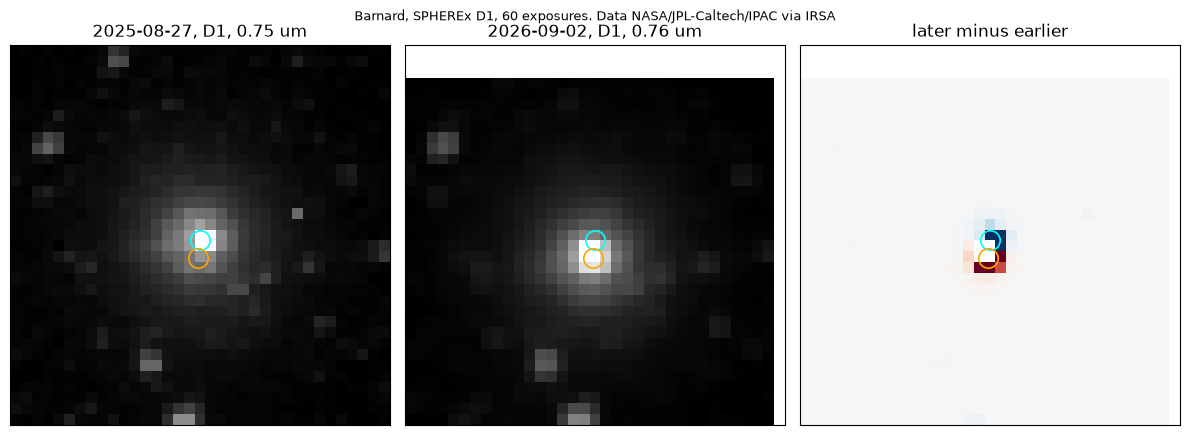

predicted shift 1.72 px between 2025-08-27 and 2026-09-02


In [4]:
def blink(name, band, size=0.06):
    rows = exposures(name, band)
    A, B = cutout(name, band, rows[0], size), cutout(name, band, rows[-1], size)
    ny, nx = A["img"].shape
    yy, xx = np.mgrid[0:ny, 0:nx]
    bx, by = B["wcs"].world_to_pixel(A["wcs"].pixel_to_world(xx, yy))
    Bon = map_coordinates(B["img"], [by, bx], order=1, cval=np.nan)

    fig, ax = plt.subplots(1, 3, figsize=(12, 4.4))
    lo, hi = np.nanpercentile(A["img"], [1, 99.9])
    lw = max(np.nanpercentile(A["img"], 84) - np.nanmedian(A["img"]), 1e-3)
    for k, (im, S) in enumerate([(A["img"], A), (Bon, B)]):
        ax[k].imshow(im, origin="lower", cmap="gray", norm=AsinhNorm(linear_width=lw, vmin=lo, vmax=hi))
        wl = S["spec"].pixel_to_world(nx // 2, ny // 2)[0].to_value("um")
        ax[k].set_title(f"{S['date']}, {band}, {wl:.2f} um")
    d = Bon - A["img"]; m = np.nanpercentile(np.abs(d), 99.5)
    ax[2].imshow(d, origin="lower", cmap="RdBu_r", vmin=-m, vmax=m); ax[2].set_title("later minus earlier")
    for a in ax:
        for S, c in [(A, "cyan"), (B, "orange")]:
            a.plot(*A["wcs"].world_to_pixel_values(*S["radec"]), "o", mfc="none", mec=c, ms=14, mew=1.2)
        a.set_xticks([]); a.set_yticks([])
    fig.suptitle(f"{name}, SPHEREx {band}, {len(rows)} exposures. Data NASA/JPL-Caltech/IPAC via IRSA", fontsize=9)
    plt.tight_layout(); plt.show()
    x0, y0 = A["wcs"].world_to_pixel_values(*A["radec"]); x1, y1 = A["wcs"].world_to_pixel_values(*B["radec"])
    print(f"predicted shift {np.hypot(x1 - x0, y1 - y0):.2f} px between {A['date']} and {B['date']}")

blink("Barnard", "D1")

## 2. The track of the star, exposure by exposure

A motion of two pixels is hard to see by eye, but easy to measure. For every exposure I take a 5 x 5 box around the predicted pixel, subtract the median of the cutout, and compute the flux-weighted centroid, the same idea as the centroids of Lab 2. Then I plot the measured offsets from the Gaia 2016 position against time, with the Gaia proper motion as a line. Barnard's Star saturates the core of D1, the brightest pixel carries the OVERFLOW flag and a few pixels are NaN, so the centroid skips those pixels instead of throwing the frame away. A saturated core makes each point a little rougher, which is why many exposures matter more than one.

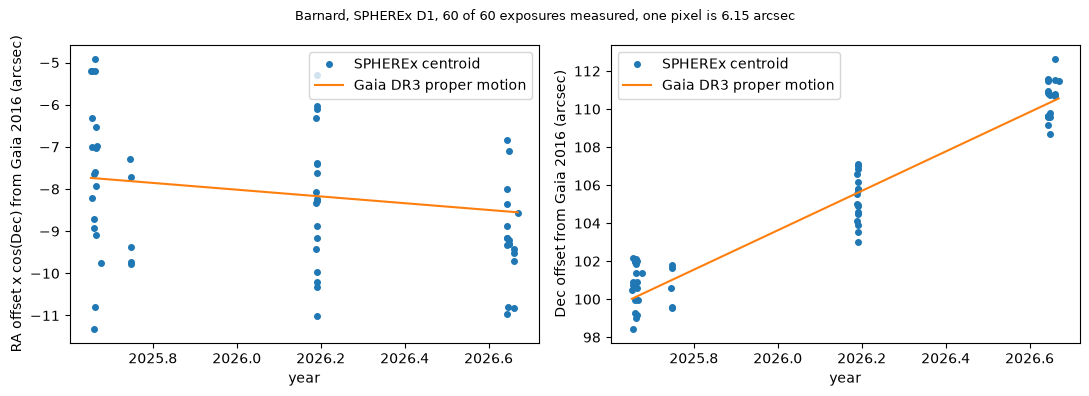

median distance from the Gaia prediction 1.79 arcsec, 0.29 px


In [5]:
def track(name, band, size=0.03):
    rows = exposures(name, band)
    frames = many(name, band, rows, size)
    ra0, dec0, ep, pmra, pmdec, _ = TARGETS[name]
    t, dx, dy = [], [], []
    for S in frames:
        x, y = S["wcs"].world_to_pixel_values(*S["radec"])
        ix, iy = int(round(float(x))), int(round(float(y)))
        img = S["img"]
        if not (2 <= ix < img.shape[1] - 2 and 2 <= iy < img.shape[0] - 2):
            continue
        box = img[iy - 2:iy + 3, ix - 2:ix + 3] - np.nanmedian(img)
        # a bright star leaves a few NaN or overflow pixels, skip them instead of the whole frame
        w = np.where(np.isfinite(box), np.clip(box, 0, None), 0.0)
        if np.isfinite(box).sum() < 15 or w.sum() <= 0:
            continue
        yy, xx = np.mgrid[iy - 2:iy + 3, ix - 2:ix + 3]
        cx, cy = (w * xx).sum() / w.sum(), (w * yy).sum() / w.sum()
        sky = S["wcs"].pixel_to_world(cx, cy)
        t.append(S["year"])
        dx.append((sky.ra.deg - ra0) * np.cos(np.radians(dec0)) * 3600)
        dy.append((sky.dec.deg - dec0) * 3600)
    t, dx, dy = map(np.array, (t, dx, dy))
    tt = np.linspace(t.min(), t.max(), 50)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for a, v, pm, lab in [(ax[0], dx, pmra, "RA offset x cos(Dec)"), (ax[1], dy, pmdec, "Dec offset")]:
        a.plot(t, v, "o", ms=4, label="SPHEREx centroid")
        a.plot(tt, pm / 1e3 * (tt - ep), "-", label="Gaia DR3 proper motion")
        a.set_xlabel("year"); a.set_ylabel(f"{lab} from Gaia 2016 (arcsec)"); a.legend()
    fig.suptitle(f"{name}, SPHEREx {band}, {len(t)} of {len(frames)} exposures measured, one pixel is {PIX} arcsec", fontsize=9)
    plt.tight_layout(); plt.show()
    res = np.hypot(dx - pmra / 1e3 * (t - ep), dy - pmdec / 1e3 * (t - ep))
    print(f"median distance from the Gaia prediction {np.median(res):.2f} arcsec, {np.median(res) / PIX:.2f} px")

track("Barnard", "D1")

## 3. Co-adding one pass, for a faint target

WISE 0855 is lost in one D6 exposure. Here every exposure of each pass is resampled onto a north-up grid centred on where the target is at the mean date of that pass, weighted by the inverse variance with the bad flags removed, and only pixels between `wlmin` and `wlmax` are used. The passes are split at the largest gap in time.

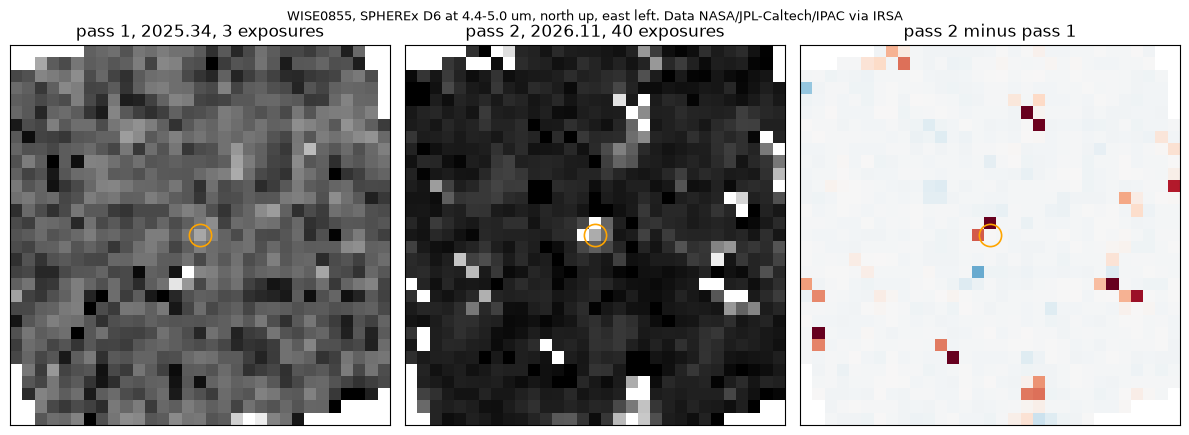

In [6]:
def coadd(name, band, wlmin, wlmax, npix=31, size=0.06):
    rows = exposures(name, band)
    frames = many(name, band, rows, size)
    t = np.array([S["year"] for S in frames])
    split = int(np.argmax(np.diff(t))) + 1

    def stack(items):
        year = np.mean([S["year"] for S in items]); ra, dec = position(name, year)
        g = WCS(naxis=2); g.wcs.ctype = ["RA---TAN", "DEC--TAN"]; g.wcs.crval = [ra, dec]
        g.wcs.crpix = [npix // 2 + 1] * 2; g.wcs.cdelt = [-PIX / 3600, PIX / 3600]
        yy, xx = np.mgrid[0:npix, 0:npix]; sky = g.pixel_to_world(xx, yy)
        num = np.zeros((npix, npix)); den = np.zeros((npix, npix)); used = 0
        for S in items:
            wl = S["spec"].pixel_to_world(*S["wcs"].world_to_pixel_values(ra, dec))[0].to_value("um")
            if not wlmin <= wl <= wlmax:
                continue
            x, y = S["wcs"].world_to_pixel(sky)
            ivar = 1 / S["h"]["VARIANCE"].data
            ivar[(S["h"]["FLAGS"].data & BAD) != 0] = 0
            v = map_coordinates(S["img"], [y, x], order=1, cval=np.nan)
            w = map_coordinates(ivar, [y, x], order=0, cval=0)
            ok = np.isfinite(v) & (w > 0)
            num[ok] += v[ok] * w[ok]; den[ok] += w[ok]; used += 1
        return np.where(den > 0, num / den, np.nan), used, year

    P = [stack(frames[:split]), stack(frames[split:])]
    fig, ax = plt.subplots(1, 3, figsize=(12, 4.4))
    lo, hi = np.nanpercentile(P[0][0], [1, 99.8])
    lw = max(np.nanpercentile(P[0][0], 84) - np.nanmedian(P[0][0]), 1e-4)
    for k, (im, used, year) in enumerate(P):
        ax[k].imshow(im, origin="lower", cmap="gray", norm=AsinhNorm(linear_width=lw, vmin=lo, vmax=hi))
        ax[k].set_title(f"pass {k + 1}, {year:.2f}, {used} exposures")
    d = P[1][0] - P[0][0]; m = np.nanpercentile(np.abs(d), 99.5)
    ax[2].imshow(d, origin="lower", cmap="RdBu_r", vmin=-m, vmax=m); ax[2].set_title("pass 2 minus pass 1")
    for a in ax:
        a.plot(npix // 2, npix // 2, "o", mfc="none", mec="orange", ms=16, mew=1.2); a.set_xticks([]); a.set_yticks([])
    fig.suptitle(f"{name}, SPHEREx {band} at {wlmin}-{wlmax} um, north up, east left. Data NASA/JPL-Caltech/IPAC via IRSA", fontsize=9)
    plt.tight_layout(); plt.show()

coadd("WISE0855", "D6", 4.4, 5.0)

## 4. Who else is in the pixel

Before calling anything a detection, I ask Gaia DR3 at IRSA what sits within a few pixels of the target on the date I care about. Near WISE 0855 in 2026 there is a star of G 16.3 only one pixel away, so the co-add above is a blend, not a clean detection.

In [7]:
def neighbours(name, year=2026.0, radius_arcsec=20):
    ra, dec = position(name, year)
    rows = tap(f'''SELECT ra, dec, phot_g_mean_mag, parallax FROM gaia_dr3_source
        WHERE 1 = CONTAINS(POINT('ICRS', ra, dec), CIRCLE('ICRS', {ra}, {dec}, {radius_arcsec / 3600}))''')
    for r in rows:
        sep = np.hypot((float(r["ra"]) - ra) * np.cos(np.radians(dec)), float(r["dec"]) - dec) * 3600
        print(f"G {float(r['phot_g_mean_mag']):5.2f}  {sep:5.1f} arcsec = {sep / PIX:.1f} px  at {float(r['ra']):.5f}, {float(r['dec']):.5f}")
    if not rows:
        print("no Gaia DR3 source within", radius_arcsec, "arcsec")

neighbours("WISE0855")

G 16.31    6.5 arcsec = 1.1 px  at 133.75818, -7.24116


## Try the others

Change the name and the detector. Epsilon Indi B moves about one pixel in total, so expect a dipole in `blink`. RW Aurigae and R Draconis do not move, they change brightness, so the interesting plot for them is the flux at fixed wavelength over time, which I build on the weekend.

In [8]:
# blink("EpsIndB", "D5", size=0.08)
# blink("RDra", "D3")
# neighbours("EpsIndB")